# Predicting High-Selling Video Games
### Team Members
### Carlos Olvera, Chris Mathews, Jared Baron Panares, Carlos Galindo

### The Problem trying to solve
### 1. Introduction

Our goal is to predict whether a video game will be a high-selling
title based on information about the game.

### Prediction: High-selling game prediction — Classification

We define a high-selling game as a game that sells at least
1 million copies globally.

Target:
- 1 = High-Selling (≥ 1 million copies)
- 0 = Not High-Selling (< 1 million copies)

We will compare K-Nearest Neighbors and Decision Tree classifiers.

In [179]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

## Part 1: Initial Data Exploration

In [180]:
videogame_df = pd.read_csv("VideoGameAnalysis-2024.csv")
videogame_df.head()
original_df = videogame_df.copy()

In [181]:
# Initial Data Exploration
videogame_df.shape
videogame_df.info()
videogame_df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64016 entries, 0 to 64015
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   img           64016 non-null  object 
 1   title         64016 non-null  object 
 2   console       64016 non-null  object 
 3   genre         64016 non-null  object 
 4   publisher     64016 non-null  object 
 5   developer     63999 non-null  object 
 6   critic_score  6678 non-null   float64
 7   total_sales   18922 non-null  float64
 8   na_sales      12637 non-null  float64
 9   jp_sales      6726 non-null   float64
 10  pal_sales     12824 non-null  float64
 11  other_sales   15128 non-null  float64
 12  release_date  56965 non-null  object 
 13  last_update   17879 non-null  object 
dtypes: float64(6), object(8)
memory usage: 6.8+ MB


,img,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
count,64016,64016,64016,64016,64016,63999,6678.000000,18922.000000,12637.000000,6726.000000,12824.000000,15128.000000,56965,17879
unique,56177,39798,81,20,3383,8862,NaN,NaN,NaN,NaN,NaN,NaN,7922,1545
top,/games/boxart/default.jpg,Plants vs. Zombies,PC,Misc,Unknown,Unknown,NaN,NaN,NaN,NaN,NaN,NaN,1994-01-01,2018-01-06
freq,7810,17,12617,9304,8842,4435,NaN,NaN,NaN,NaN,NaN,NaN,515,165
mean,NaN,NaN,NaN,NaN,NaN,NaN,7.220440,0.349113,0.264740,0.102281,0.149472,0.043041,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,1.457066,0.807462,0.494787,0.168811,0.392653,0.126643,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,6.400000,0.030000,0.050000,0.020000,0.010000,0.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,7.500000,0.120000,0.120000,0.040000,0.040000,0.010000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,8.300000,0.340000,0.280000,0.120000,0.140000,0.030000,NaN,NaN


In [182]:
#Examine missing values
missing = pd.DataFrame({
    "Missing Count": videogame_df.isnull().sum(),
    "Missing Percent": videogame_df.isnull().mean() * 100
})

missing.sort_values("Missing Percent", ascending=False)

,Missing Count,Missing Percent
critic_score,57338,89.568233
jp_sales,57290,89.493252
na_sales,51379,80.259623
pal_sales,51192,79.967508
other_sales,48888,76.368408
last_update,46137,72.071045
total_sales,45094,70.441765
release_date,7051,11.014434
developer,17,0.026556
publisher,0,0.000000


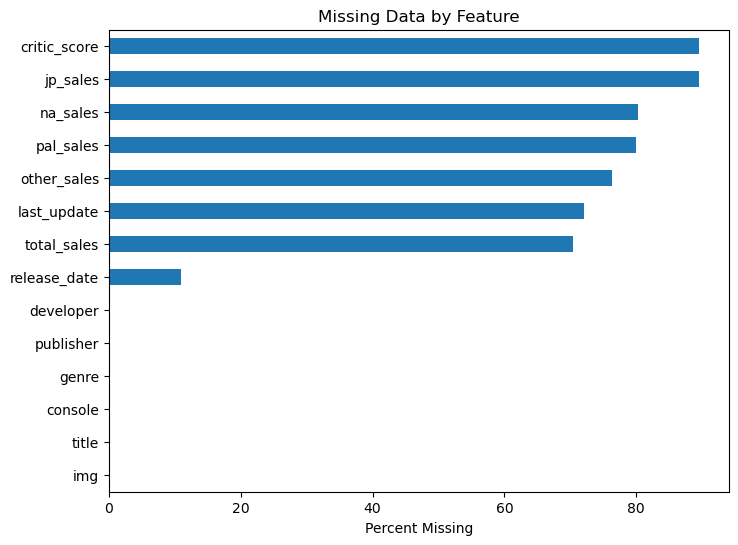

In [183]:
missing["Missing Percent"].sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Percent Missing")
plt.title("Missing Data by Feature")
plt.show()

In [184]:
#inspect category counts
print(f"Genre: {videogame_df['genre'].value_counts().shape[0]}")
print(f"Console: {videogame_df['console'].value_counts().shape[0]}")
print(f"Publisher: {videogame_df['publisher'].nunique()}")
print(f"Developer: {videogame_df['developer'].nunique()}")

Genre: 20
Console: 81
Publisher: 3383
Developer: 8862


# Part 2: Data Cleaning


### Target Variable Creation

We use total_sales to determine whether each historical game was
high-selling. Games with missing total_sales cannot be labeled and
are therefore removed.

After creating the Labels, total_sales is removed from the predictors
to prevent data leakage.

Done so total_sales feature will not dominate prediction

In [185]:
videogame_df = videogame_df.dropna(subset=["total_sales"])

videogame_df["label_highselling"] = (
    videogame_df["total_sales"] >= 1.0
).astype(int)

In [186]:
videogame_df["label_highselling"].value_counts()
videogame_df["label_highselling"].value_counts(normalize=True) * 100

label_highselling
0    92.046295
1     7.953705
Name: proportion, dtype: float64

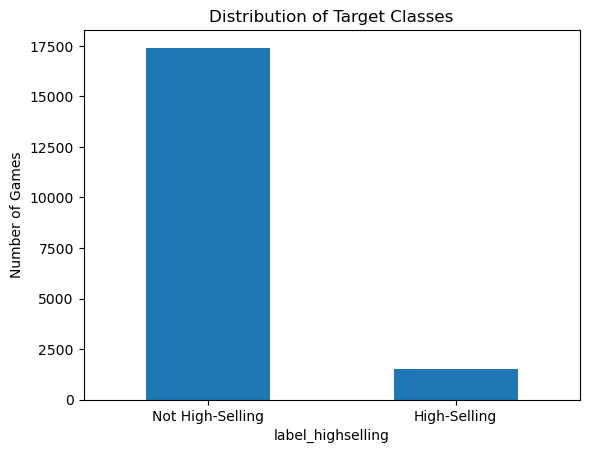

In [187]:
videogame_df["label_highselling"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xticks([0, 1], ["Not High-Selling", "High-Selling"], rotation=0)
plt.ylabel("Number of Games")
plt.title("Distribution of Target Classes")
plt.show()

The graph because it shows the 92% vs. 8% imbalance

In [188]:
videogame_df = videogame_df.drop(
    columns=[
        "img",
        "total_sales",
        "na_sales",
        "jp_sales",
        "pal_sales",
        "other_sales"
    ]
)

game_titles = original_df.loc[videogame_df.index, "title"]


In [191]:
#Examine missing values
missing = pd.DataFrame({
    "Missing Count": videogame_df.isnull().sum(),
    "Missing Percent": videogame_df.isnull().mean() * 100
})

missing.sort_values("Missing Percent", ascending=False)

,Missing Count,Missing Percent
last_update,14895,78.763683
critic_score,14785,78.182010
release_date,90,0.475913
developer,4,0.021152
title,0,0.000000
publisher,0,0.000000
genre,0,0.000000
console,0,0.000000
label_highselling,0,0.000000


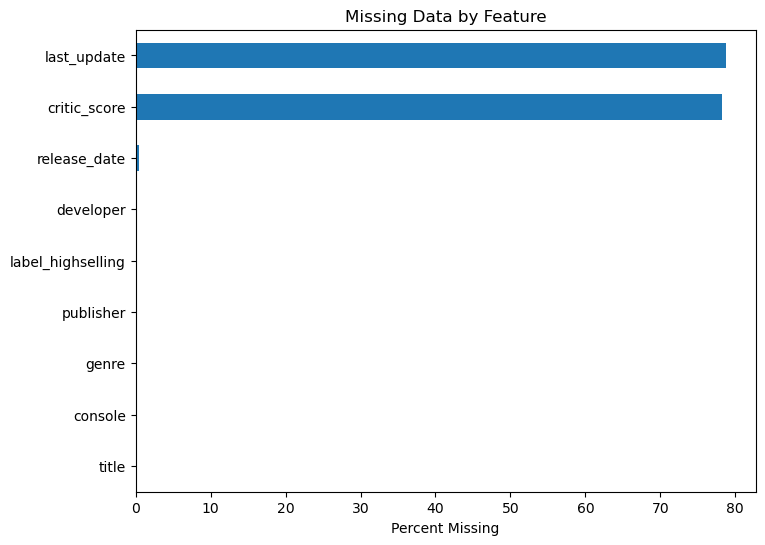

In [192]:
missing["Missing Percent"].sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Percent Missing")
plt.title("Missing Data by Feature")
plt.show()

In [193]:
# Feartures to use for modeling
features = [
    "console",
    "genre",
    "publisher",
    "developer",
    "critic_score",
    "release_date",
    "label_highselling"
]

videogame_df = videogame_df[features]

### Duplicate Records
There were 11 duplicates, we reduced it to 0 so there would not be any unneeded data

In [ ]:
duplicate_count = videogame_df.duplicated().sum()
videogame_df = videogame_df.drop_duplicates()
print("Number of duplicate records:", duplicate_count)

In [ ]:
duplicate_count = videogame_df.duplicated().sum()
print("Number of duplicate records:", duplicate_count)

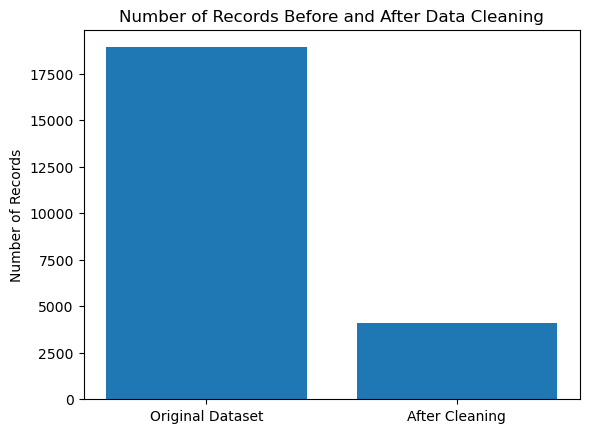

In [194]:
#The amount of records we are going to use after removing unnecessary columns and dropping rows with missing values
original_records = len(videogame_df)

# Remove any row that has at least one missing value
videogame_df = videogame_df.dropna()

remaining_records = len(videogame_df)

# Compare the number of records before and after data cleaning

plt.bar(
    ["Original Dataset", "After Cleaning"],
    [original_records, remaining_records]
)

plt.title("Number of Records Before and After Data Cleaning")
plt.ylabel("Number of Records")

plt.show()

## part 3 Feature Engineering